评论长度统计：
        count    mean  median     std
Score                                
1       51965  463.99   336.0  465.76
2       29753  490.40   357.0  457.76
3       42558  519.47   373.0  507.59
4       80550  496.39   346.0  484.36
5      362319  401.01   277.0  407.23


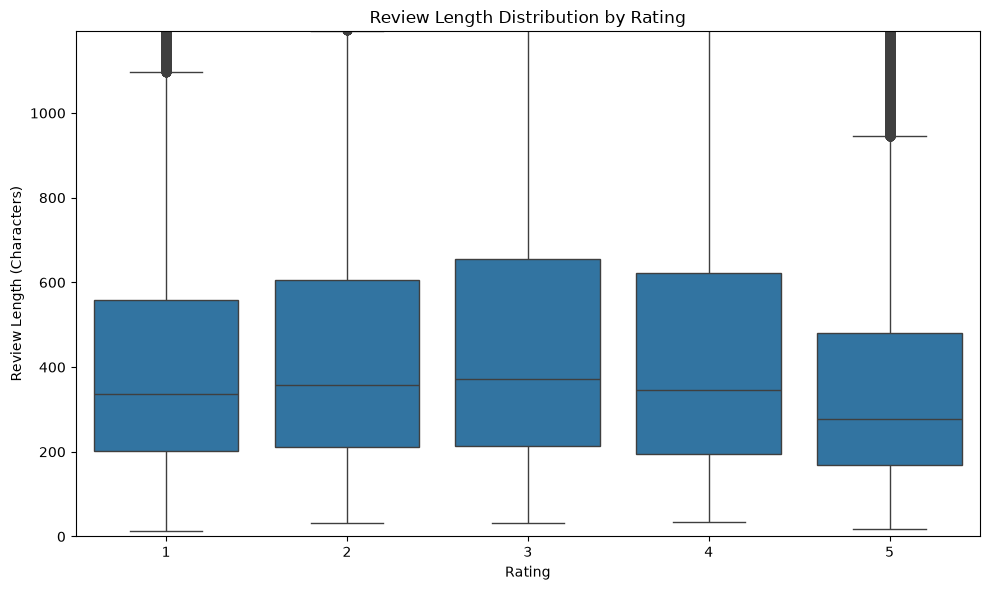

In [3]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 1. 加载清洗后的数据
df = pd.read_csv("../data/processed/reviews_cleaned.csv")

# 2. 计算评论长度
df["Text_Length"] = df["Text"].astype(str).apply(len)

# 3. 按评分统计评论长度
length_stats = df.groupby("Score")["Text_Length"].agg(
    ["count", "mean", "median", "std"]
)

print("评论长度统计：")
print(length_stats.round(2))

# 4. 可视化不同评分的评论长度分布
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Score",
    y="Text_Length"
)

plt.title("Review Length Distribution by Rating")
plt.xlabel("Rating")
plt.ylabel("Review Length (Characters)")
plt.ylim(0, df["Text_Length"].quantile(0.95))

plt.tight_layout()

# 5. 保存图片
output_dir = Path("../results/figures")
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "review_length_by_rating.png",
    dpi=300
)

plt.show()


In [9]:
print("vectorizer:", "vectorizer" in globals())
print("lr_model:", "lr_model" in globals())
print("numpy:", "np" in globals())
print("pandas:", "pd" in globals())

# 1. 获取 TF-IDF 特征名称
feature_names = vectorizer.get_feature_names_out()

# 2. 获取模型系数
coefficients = lr_model.coef_

# 3. 每个评分类别提取权重最高的 15 个词
top_features = {}

for index, rating in enumerate(lr_model.classes_):
    top_indices = np.argsort(coefficients[index])[-15:][::-1]

    top_features[f"{rating} star"] = [
        (feature_names[i], coefficients[index][i])
        for i in top_indices
    ]

# 4. 输出结果
for rating, features in top_features.items():
    print(f"\n========== {rating} ==========")

    for word, weight in features:
        print(f"{word:<25} {weight:.4f}")

# 5. 保存特征分析结果
rows = []

for rating, features in top_features.items():
    for word, weight in features:
        rows.append({
            "Rating": rating,
            "Feature": word,
            "Coefficient": weight
        })

feature_df = pd.DataFrame(rows)

feature_df.to_csv(
    "../results/metrics/top_text_features.csv",
    index=False
)

print("\n特征分析结果已保存！")


vectorizer: True
lr_model: True
numpy: True
pandas: True

========== 1 star ==========
awful                     8.3184
terrible                  8.1445
disgusting                7.4526
one star                  7.4201
worst                     6.9164
horrible                  6.7809
gross                     6.5089
nasty                     6.5029
not recommend             6.4223
threw                     6.1062
yuck                      6.0970
not good                  5.6822
worse                     5.3048
not worth                 5.2574
return                    5.2015

========== 2 star ==========
two stars                 13.5653
disappointing             6.2935
disappointed              4.9745
weak                      4.6826
not impressed             4.5569
mediocre                  4.5359
not worth                 4.5008
disappointment            4.4510
not very                  4.3045
unfortunately             4.2937
not recommend             4.0983
it two                  

In [5]:
print("vectorizer:", "vectorizer" in globals())
print("lr_model:", "lr_model" in globals())

print("当前变量：", [
    name for name in globals()
    if name in ["vectorizer", "lr_model"]
])

vectorizer: False
lr_model: False
当前变量： []


In [6]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# 1. 加载数据
df = pd.read_csv("../data/processed/reviews_cleaned.csv")
df = df.dropna(subset=["Text", "Score"])

X = df["Text"].astype(str)
y = df["Score"].astype(int)

# 2. 划分数据集
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("数据集划分完成")

# 3. TF-IDF
vectorizer = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = vectorizer.fit_transform(X_train)

print("TF-IDF 特征提取完成")

# 4. 训练模型
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    solver="lbfgs"
)

lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression 训练完成")
print("特征数量：", len(vectorizer.get_feature_names_out()))

# 5. 检查变量
print("vectorizer:", "vectorizer" in globals())
print("lr_model:", "lr_model" in globals())


数据集划分完成
TF-IDF 特征提取完成
Logistic Regression 训练完成
特征数量： 20000
vectorizer: True
lr_model: True


In [8]:
import numpy as np

# 1. 获取 TF-IDF 特征名称
feature_names = vectorizer.get_feature_names_out()

# 2. 获取模型系数
coefficients = lr_model.coef_

# 3. 提取每个评分的 Top 15 特征词
top_features = {}

for index, rating in enumerate(lr_model.classes_):
    top_indices = np.argsort(coefficients[index])[-15:][::-1]

    top_features[f"{rating} star"] = [
        (feature_names[i], coefficients[index][i])
        for i in top_indices
    ]

# 4. 输出结果
for rating, features in top_features.items():
    print(f"\n========== {rating} ==========")

    for word, weight in features:
        print(f"{word:<25} {weight:.4f}")

# 5. 保存结果
rows = []

for rating, features in top_features.items():
    for word, weight in features:
        rows.append({
            "Rating": rating,
            "Feature": word,
            "Coefficient": weight
        })

feature_df = pd.DataFrame(rows)

feature_df.to_csv(
    "../results/metrics/top_text_features.csv",
    index=False
)

print("\n特征分析结果已保存！")


========== 1 star ==========
awful                     8.3184
terrible                  8.1445
disgusting                7.4526
one star                  7.4201
worst                     6.9164
horrible                  6.7809
gross                     6.5089
nasty                     6.5029
not recommend             6.4223
threw                     6.1062
yuck                      6.0970
not good                  5.6822
worse                     5.3048
not worth                 5.2574
return                    5.2015

========== 2 star ==========
two stars                 13.5653
disappointing             6.2935
disappointed              4.9745
weak                      4.6826
not impressed             4.5569
mediocre                  4.5359
not worth                 4.5008
disappointment            4.4510
not very                  4.3045
unfortunately             4.2937
not recommend             4.0983
it two                    4.0406
not good                  4.0128
not            